In [36]:
import pandas as pd
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import matplotlib.pyplot as plt
import seaborn as sns


In [37]:
df=pd.read_csv("loan_approval_data.csv")
df

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2.0,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,NaN,Car,Semiurban,Graduate,NaN,Private,No
2,3.0,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,NaN,Urban,NaN,Female,Government,Yes
3,4.0,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,5.0,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,NaN,Graduate,Male,Private,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,996.0,NaN,9092.0,Salaried,58.0,Married,0.0,557.0,0.0,0.59,5370.0,43563.0,8311.0,72.0,Personal,NaN,Not Graduate,Male,Unemployed,No
996,997.0,3279.0,6356.0,Self-employed,58.0,Married,1.0,646.0,3.0,0.19,NaN,18361.0,22563.0,12.0,Business,Urban,Graduate,Female,Government,No
997,998.0,15192.0,8433.0,Contract,48.0,Single,1.0,666.0,1.0,0.40,8581.0,41335.0,16203.0,24.0,Home,Rural,Graduate,Male,MNC,No
998,999.0,9083.0,7380.0,Unemployed,50.0,Single,1.0,748.0,3.0,0.31,13491.0,8933.0,10290.0,36.0,Personal,Urban,Graduate,Male,Private,Yes


In [38]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        950 non-null    float64
 1   Applicant_Income    950 non-null    float64
 2   Coapplicant_Income  950 non-null    float64
 3   Employment_Status   950 non-null    object 
 4   Age                 950 non-null    float64
 5   Marital_Status      950 non-null    object 
 6   Dependents          950 non-null    float64
 7   Credit_Score        950 non-null    float64
 8   Existing_Loans      950 non-null    float64
 9   DTI_Ratio           950 non-null    float64
 10  Savings             950 non-null    float64
 11  Collateral_Value    950 non-null    float64
 12  Loan_Amount         950 non-null    float64
 13  Loan_Term           950 non-null    float64
 14  Loan_Purpose        950 non-null    object 
 15  Property_Area       950 non-null    object 
 16  Educati

In [39]:
df.isna().sum()

Applicant_ID          50
Applicant_Income      50
Coapplicant_Income    50
Employment_Status     50
Age                   50
Marital_Status        50
Dependents            50
Credit_Score          50
Existing_Loans        50
DTI_Ratio             50
Savings               50
Collateral_Value      50
Loan_Amount           50
Loan_Term             50
Loan_Purpose          50
Property_Area         50
Education_Level       50
Gender                50
Employer_Category     50
Loan_Approved         50
dtype: int64

In [41]:
print("Duplicate rows:", df.duplicated().sum())


Duplicate rows: 0


# Exploratory-Data-Analysis

<Axes: xlabel='Loan_Approved', ylabel='count'>

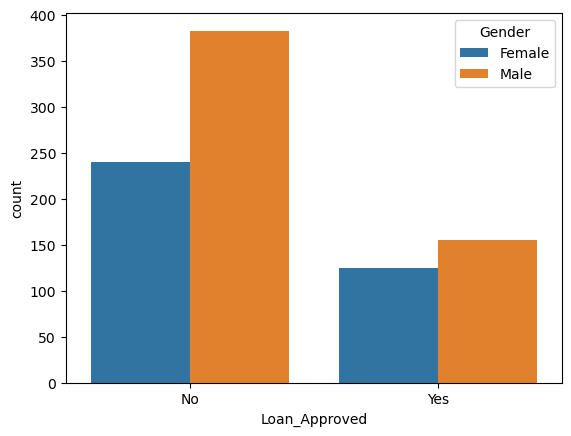

In [43]:
sns.countplot(
    data=df,
    x="Loan_Approved",
    hue="Gender"
)

<Axes: xlabel='Gender', ylabel='count'>

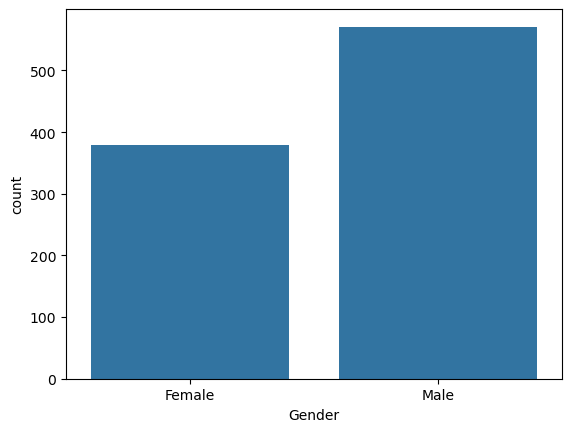

In [44]:
sns.countplot(
    data=df,
    x="Gender",
    
)

<Axes: xlabel='Education_Level', ylabel='count'>

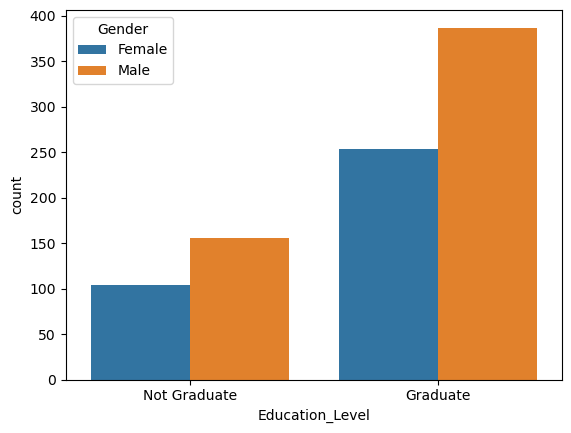

In [46]:
sns.countplot(
    data=df,
    x="Education_Level",
    hue="Gender"
    
)

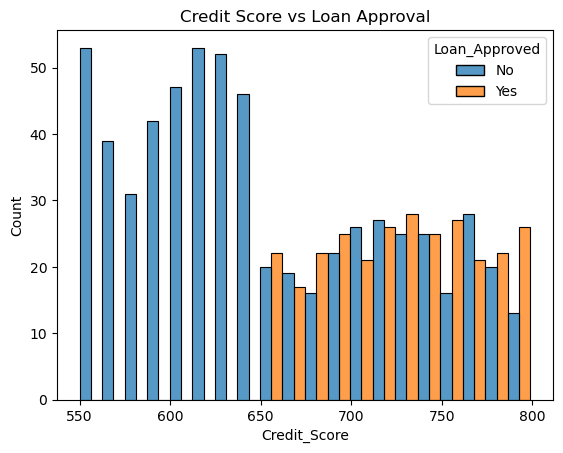

In [47]:
sns.histplot(
    data=df,
    x="Credit_Score",
    bins=20,
    hue="Loan_Approved",
    multiple="dodge"
)
plt.title("Credit Score vs Loan Approval")
plt.show()


# Handling-Missing-Values

In [49]:
df = df.dropna(subset=["Loan_Approved"]).copy()

x= df.drop(columns=["Applicant_ID", "Loan_Approved"], errors="ignore")
y = df["Loan_Approved"]

print("Feature shape:", X.shape)
print("Target distribution:")
display(y.value_counts())


Feature shape: (950, 18)
Target distribution:


Loan_Approved
No     652
Yes    298
Name: count, dtype: int64

In [53]:
x_train,x_test,y_train,y_test=train_test_split(
    x,y,random_state=42,test_size=0.2,stratify=y)
numerical_features=x_train.select_dtypes(include=["number"]).columns
categorical_features=x_train.select_dtypes(include=["object","category","bool"]).columns

In [54]:
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])


categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        drop="first",
        handle_unknown="ignore"
    ))
])
preprocessor=ColumnTransformer(transformers=[("num",numerical_transformer,numerical_features),
                                             ("cat",categorical_transformer,categorical_features)
                                            ])


# Training

In [55]:
model=Pipeline(steps=[
    ("preprocessor",preprocessor),
    ("classifier",DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ))
])
model  

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [59]:
param_grid = {
    "classifier__ccp_alpha": [0.0, 0.00001, 0.0001, 0.001, 0.005, 0.01, 0.02, 0.05]
}

grid = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=1
)

grid.fit(x_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best cross-validation macro F1:", grid.best_score_)


Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best parameters: {'classifier__ccp_alpha': 0.005}
Best cross-validation macro F1: 0.9581624408982456


In [61]:
y_pred = grid.predict(x_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("\\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))


Test accuracy: 0.968421052631579
\nClassification report:
              precision    recall  f1-score   support

          No       0.99      0.96      0.98       130
         Yes       0.92      0.98      0.95        60

    accuracy                           0.97       190
   macro avg       0.96      0.97      0.96       190
weighted avg       0.97      0.97      0.97       190



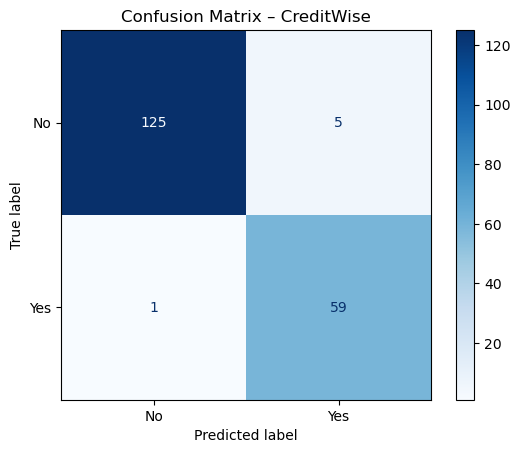

In [62]:
cm = confusion_matrix(y_test, y_pred, labels=grid.classes_)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=grid.classes_
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix – CreditWise")
plt.show()